# Paso 7 – Clustering **versión 1**: perfil completo con edad y sexo (Gower)

**Dataset:** `Resultados_EnfoqueB/Dataset_final_enfoqueB.xlsx`, generado por *Paso 4B – Transformación final Enfoque B*: 161 NNA presentes entre 2025-01 y 2026-07, con su último mes registrado más el resumen de su historial.

**Idea de esta versión:** agrupar con las **13 variables del modelo base**, que incluyen la **edad** y el **sexo**. El documento de referencia pide *contrastar individualmente el uso de edad y sexo*; esta versión es el punto de partida y, en la sección 9, se mide qué pasa al quitar cada una por separado. La versión 2 las quita a las dos.

**Modelos** (como en los cuadernos de *Ejemplos clustering*, adaptados a datos mixtos):
1. **AGNES** (jerárquico aglomerativo) sobre la distancia de Gower.
2. **PAM / K-Medoids** sobre Gower.
3. **K-Prototypes** (k-means para datos mixtos).
4. **HDBSCAN** (basado en densidad) sobre Gower.

Se comparan por **separación y cohesión** (silueta, distancia intra e inter-cluster, índice de Dunn), **estabilidad** (remuestreo) e **interpretabilidad**.

# 1. Librerías y lectura del dataset de la versión

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, fcluster, cophenet, dendrogram
from scipy.spatial.distance import squareform
from scipy.stats import chi2_contingency
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.cluster import HDBSCAN
from sklearn.manifold import MDS
from kmodes.kprototypes import KPrototypes

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

VERSION = 'v1'
BASE = Path.cwd().parent if Path.cwd().name == 'Notebooks' else Path.cwd()
RUTA = BASE / 'Resultados_EnfoqueB'
X = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='dataset').set_index('id_persona')
versiones = pd.read_excel(RUTA / 'Dataset_final_enfoqueB.xlsx', sheet_name='versiones')
TIPOS = dict(versiones.loc[versiones['version'] == VERSION, ['variable', 'tipo_gower']].values)
VARS = list(TIPOS)
N = len(X)
print(f'Versión {VERSION}: {N} NNA | {len(VARS)} variables')
pd.DataFrame({'tipo': TIPOS, 'vacíos': X[VARS].isna().sum(), 'valores distintos': X[VARS].nunique()})

Versión v1: 161 NNA | 13 variables


,tipo,vacíos,valores distintos
ln_permanencia,num,0,103
edad_modelo,num,0,137
sexo,cat,0,2
procedencia_provincias,bin,0,2
salud_fisica_cronica,bin,0,2
presenta_discapacidad,bin,0,2
nivel_atencion_salud_mental,ord,0,4
flag_rezago_escolar,bin,0,2
estado_pti,cat,0,4
situacion_juridica,cat,0,4


**Tipos para Gower:** `num` (numérica, normalizada por su rango), `ord` (ordinal, tratada como numérica normalizada para que la distancia entre niveles extremos sea mayor), `cat` y `bin` (coincidencia simple: 0 si son iguales, 1 si difieren). Las binarias se tratan de forma **simétrica**, es decir, que dos NNA coincidan en 0 (por ejemplo, ambas sin discapacidad) también cuenta como parecido, porque en este caso la ausencia de la condición también es informativa.

# 2. Matriz de distancias de Gower

Diferencia máxima con la librería gower: 3.19e-08
Distancias: media = 0.337 | mediana = 0.333 | mín = 0.004 | máx = 0.784


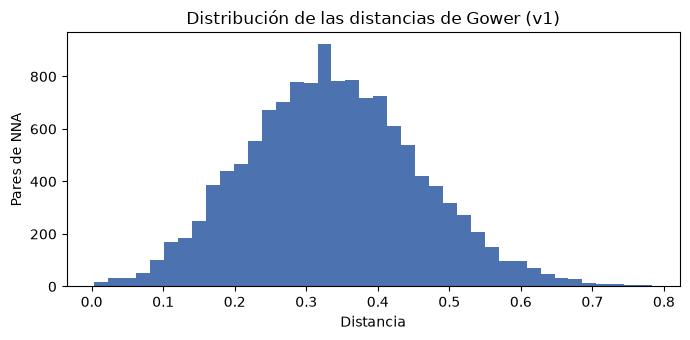

In [2]:
def gower(df, tipos):
    """Distancia de Gower. Numéricas/ordinales: |x - y| / rango. Categóricas/binarias: 0 si coinciden, 1 si no.
    Los vacíos se excluyen par a par (la distancia promedia solo las variables disponibles)."""
    n = len(df)
    num, den = np.zeros((n, n)), np.zeros((n, n))
    for c, t in tipos.items():
        x = df[c]
        ok = np.asarray(x.notna())
        valid = ok[:, None] & ok[None, :]
        if t in ('num', 'ord'):
            v = np.asarray(x, dtype=float)
            rango = np.nanmax(v) - np.nanmin(v)
            d = np.abs(v[:, None] - v[None, :]) / rango if rango > 0 else np.zeros((n, n))
        else:
            v = np.asarray(x.astype(str), dtype=object)
            d = (v[:, None] != v[None, :]).astype(float)
        num += np.where(valid, d, 0)
        den += valid
    D = num / den
    np.fill_diagonal(D, 0)
    return D


D = gower(X, TIPOS)

# Validación con la librería `gower` usada en clase (si está instalada)
try:
    import gower as gower_lib
    Xg = X[VARS].copy()
    for c in VARS:
        Xg[c] = Xg[c].astype(object) if TIPOS[c] == 'cat' else Xg[c].astype(float)
    Dlib = gower_lib.gower_matrix(Xg, cat_features=[TIPOS[c] == 'cat' for c in VARS])
    print(f'Diferencia máxima con la librería gower: {np.abs(D - Dlib).max():.2e}')
except Exception as e:
    print('No se pudo comparar con la librería gower:', e)

iu = np.triu_indices(N, 1)
print(f'Distancias: media = {D[iu].mean():.3f} | mediana = {np.median(D[iu]):.3f} | mín = {D[iu].min():.3f} | máx = {D[iu].max():.3f}')
plt.figure(figsize=(7, 3.5))
plt.hist(D[iu], bins=40, color='#4c72b0')
plt.title(f'Distribución de las distancias de Gower ({VERSION})')
plt.xlabel('Distancia')
plt.ylabel('Pares de NNA')
plt.tight_layout()
plt.show()

# 3. Funciones comunes: PAM, métricas, estabilidad y criterio de selección

- **PAM** (*Partitioning Around Medoids*) se implementa directamente (fases BUILD y SWAP), porque `scikit-learn-extra` no se instala en las versiones recientes de Python. El medoide es una NNA real que representa a su grupo.
- **Métricas internas** (todas sobre la misma matriz de Gower, para que los modelos sean comparables):
  - **Silueta** (de −1 a 1): cohesión frente a separación de cada NNA.
  - **Cohesión:** distancia media entre NNA del mismo cluster (menor es mejor).
  - **Separación:** distancia media entre NNA de clusters distintos (mayor es mejor).
  - **Dunn:** menor distancia entre clusters dividida por el mayor diámetro (mayor es mejor).
- **Estabilidad:** se remuestrea el 80 % de las NNA sin reemplazo, se vuelve a agrupar y se compara con la partición completa mediante el **ARI** (*Adjusted Rand Index*). Un ARI medio ≥ 0.75 indica una partición estable.
- **Criterio de selección de k:** el objetivo es obtener perfiles para revisiones interdisciplinarias, así que se buscan **entre 3 y 7 grupos** (2 es demasiado general y más de 7 fragmenta 161 NNA en grupos muy chicos), con un **mínimo de 8 NNA por grupo** (5 %). Entre los candidatos se elige el que maximiza el **índice combinado = silueta × ARI medio**, que premia a la vez la separación y la estabilidad.

In [3]:
def pam(D, k, max_iter=50):
    n = len(D)
    med = [int(np.argmin(D.sum(1)))]                     # BUILD: primer medoide = el más central
    for _ in range(1, k):
        dmin = D[:, med].min(1)
        ganancia = np.array([np.maximum(dmin - D[:, j], 0).sum() if j not in med else -1 for j in range(n)])
        med.append(int(np.argmax(ganancia)))
    costo = D[:, med].min(1).sum()
    for _ in range(max_iter):                            # SWAP: intercambia medoide por no medoide si baja el costo
        mejoro = False
        for i in range(k):
            for h in range(n):
                if h in med:
                    continue
                m = med.copy()
                m[i] = h
                c = D[:, m].min(1).sum()
                if c < costo - 1e-12:
                    costo, med, mejoro = c, m, True
        if not mejoro:
            break
    return np.array(med), D[:, med].argmin(1), costo


def metricas(D, lab):
    lab = np.asarray(lab)
    ks = np.unique(lab)
    mismo = lab[:, None] == lab[None, :]
    off = ~np.eye(len(D), dtype=bool)
    diam = max(D[np.ix_(lab == a, lab == a)].max() for a in ks)
    min_inter = min(D[np.ix_(lab == a, lab == b)].min() for i, a in enumerate(ks) for b in ks[i + 1:])
    return {'k': len(ks), 'silueta': silhouette_score(D, lab, metric='precomputed'),
            'cohesion_intra': D[mismo & off].mean(), 'separacion_inter': D[~mismo].mean(),
            'dunn': min_inter / diam, 'tamano_min': int(np.bincount(pd.factorize(lab)[0]).min())}


def estabilidad(ajustar, D, k, B=100, frac=0.8, semilla=0):
    """ARI medio entre la partición completa y las particiones de submuestras del 80 %."""
    rng = np.random.default_rng(semilla)
    completa = ajustar(D, k, np.arange(len(D)))
    aris = []
    for _ in range(B):
        idx = np.sort(rng.choice(len(D), int(frac * len(D)), replace=False))
        aris.append(adjusted_rand_score(completa[idx], ajustar(D[np.ix_(idx, idx)], k, idx)))
    return np.mean(aris), np.std(aris)


K_RANGO = range(2, 9)
K_CANDIDATOS = range(3, 8)
TAM_MIN = 8


def tabla_k(nombre, ajustar, B=100):
    filas = []
    for k in K_RANGO:
        lab = ajustar(D, k, np.arange(N))
        m = metricas(D, lab)
        m['ARI_medio'], m['ARI_sd'] = estabilidad(ajustar, D, k, B=B)
        filas.append(m)
    t = pd.DataFrame(filas).set_index('k')
    t['indice_combinado'] = t['silueta'] * t['ARI_medio']
    t['candidato'] = t.index.isin(K_CANDIDATOS) & (t['tamano_min'] >= TAM_MIN)
    t.insert(0, 'modelo', nombre)
    return t


def elegir_k(t):
    return int(t[t['candidato']]['indice_combinado'].idxmax())


def cramer_v(a, b):
    t = pd.crosstab(np.asarray(a), np.asarray(b))
    chi2 = chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))


def eta2(cat, num):
    d = pd.DataFrame({'c': np.asarray(cat), 'n': np.asarray(num, dtype=float)}).dropna()
    m = d['n'].mean()
    return d.groupby('c')['n'].apply(lambda s: len(s) * (s.mean() - m) ** 2).sum() / ((d['n'] - m) ** 2).sum()

# 4. Modelo 1 – AGNES (jerárquico aglomerativo) sobre Gower

El método de Ward supone distancias euclidianas, así que no corresponde con Gower. Se comparan los enlaces que sí aceptan cualquier disimilitud (promedio, completo, simple y ponderado) mediante la **correlación cofenética**, que mide qué tan bien el dendrograma conserva las distancias originales.

Correlación cofenética: {'average': np.float64(0.646), 'complete': np.float64(0.449), 'single': np.float64(0.557), 'weighted': np.float64(0.547)}


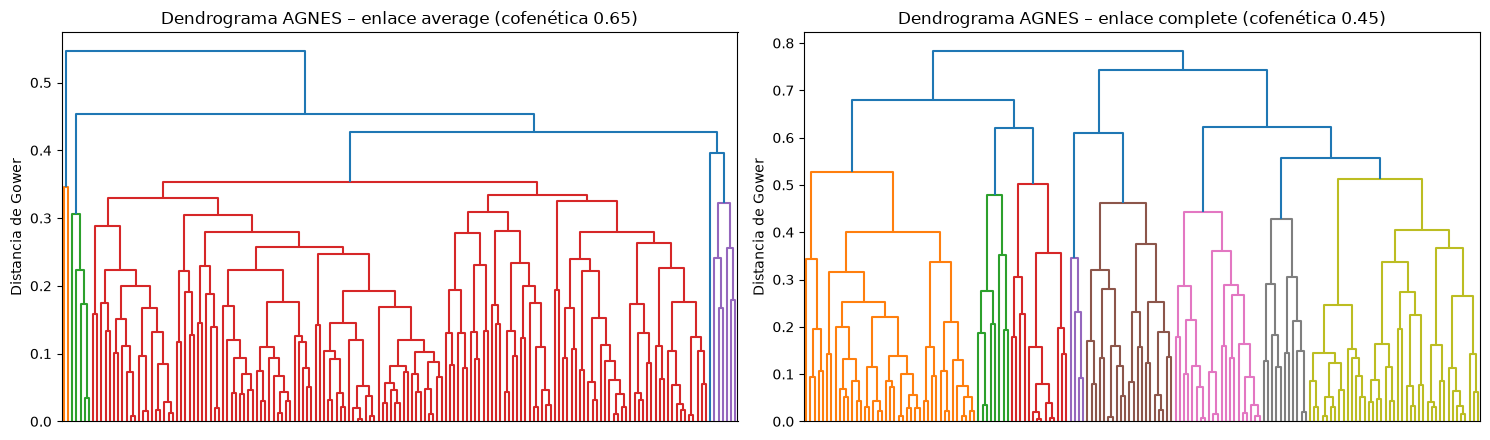

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato
k,,,,,,,,,,
2,AGNES promedio,0.367,0.332,0.547,0.288,2,0.452,0.378,0.166,False
3,AGNES promedio,0.239,0.324,0.481,0.220,2,0.542,0.230,0.129,False
4,AGNES promedio,0.209,0.314,0.455,0.215,2,0.671,0.153,0.140,False
5,AGNES promedio,0.154,0.314,0.455,0.215,1,0.533,0.160,0.082,False
6,AGNES promedio,0.157,0.277,0.382,0.128,1,0.300,0.190,0.047,False
7,AGNES promedio,0.150,0.277,0.382,0.128,1,0.336,0.225,0.050,False
8,AGNES promedio,0.148,0.265,0.377,0.136,1,0.402,0.223,0.059,False
2,AGNES completo,0.120,0.318,0.359,0.102,63,0.031,0.067,0.004,False
3,AGNES completo,0.147,0.293,0.365,0.094,25,0.128,0.102,0.019,True


In [4]:
Dc = squareform(D, checks=False)
cofe = {m: cophenet(linkage(Dc, m), Dc)[0] for m in ['average', 'complete', 'single', 'weighted']}
print('Correlación cofenética:', {m: round(v, 3) for m, v in cofe.items()})

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for a, m in zip(ax, ['average', 'complete']):
    dendrogram(linkage(Dc, m), ax=a, no_labels=True, color_threshold=None)
    a.set_title(f'Dendrograma AGNES – enlace {m} (cofenética {cofe[m]:.2f})')
    a.set_ylabel('Distancia de Gower')
plt.tight_layout()
plt.show()


def ajustar_agnes(metodo):
    return lambda Dm, k, idx: fcluster(linkage(squareform(Dm, checks=False), metodo), k, 'maxclust')


t_avg = tabla_k('AGNES promedio', ajustar_agnes('average'))
t_com = tabla_k('AGNES completo', ajustar_agnes('complete'))
pd.concat([t_avg, t_com]).round(3)

In [5]:
print('Tamaños de los grupos, enlace promedio:', {k: np.bincount(ajustar_agnes('average')(D, k, None))[1:].tolist() for k in (3, 4, 5)})

Tamaños de los grupos, enlace promedio: {3: [2, 5, 154], 4: [2, 5, 147, 7], 5: [2, 5, 147, 6, 1]}


**Comentario 4:** **AGNES no produce una partición útil en la v1.**
- El enlace **promedio** tiene la mayor correlación cofenética (0.65), pero lo que hace es **aislar atípicos**: con k = 3 deja grupos de 2, 5 y 154 NNA. Ningún k cumple el mínimo de 8 NNA por grupo.
- El enlace **completo** arma grupos más equilibrados, pero su silueta es baja (0.12 a 0.17) y es **muy inestable**: el ARI medio va de 0.03 a 0.31, así que al quitar el 20 % de las NNA la partición cambia casi por completo.
- Es la conducta típica del jerárquico cuando no hay grupos bien separados: las fusiones tempranas, que nunca se deshacen, condicionan todo el árbol.

# 5. Modelo 2 – PAM / K-Medoids sobre Gower

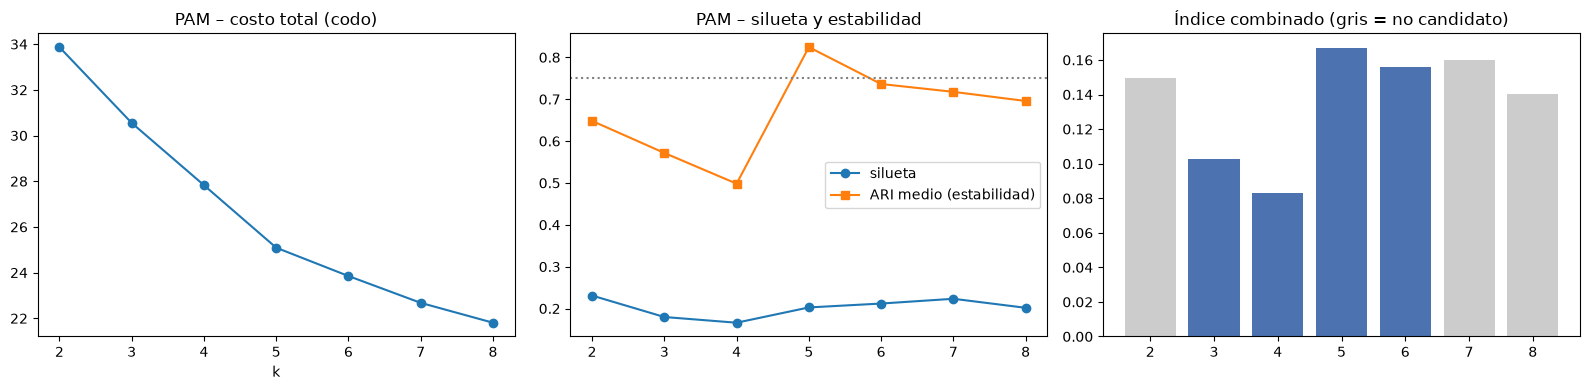

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato,costo
k,,,,,,,,,,,
2,PAM,0.231,0.295,0.381,0.131,72,0.648,0.315,0.150,False,33.870
3,PAM,0.180,0.279,0.366,0.067,49,0.572,0.316,0.103,True,30.553
4,PAM,0.166,0.268,0.361,0.015,30,0.498,0.207,0.083,True,27.827
5,PAM,0.203,0.246,0.360,0.076,26,0.824,0.207,0.167,True,25.090
6,PAM,0.212,0.232,0.360,0.078,11,0.736,0.180,0.156,True,23.850
7,PAM,0.223,0.221,0.361,0.078,6,0.718,0.167,0.160,False,22.676
8,PAM,0.202,0.217,0.358,0.036,6,0.696,0.148,0.140,False,21.807


In [6]:
ajustar_pam = lambda Dm, k, idx: pam(Dm, k)[1]
t_pam = tabla_k('PAM', ajustar_pam)
costos = {k: pam(D, k)[2] for k in K_RANGO}
t_pam['costo'] = pd.Series(costos)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(list(costos), list(costos.values()), marker='o')
ax[0].set_title('PAM – costo total (codo)')
ax[0].set_xlabel('k')
ax[1].plot(t_pam.index, t_pam['silueta'], marker='o', label='silueta')
ax[1].plot(t_pam.index, t_pam['ARI_medio'], marker='s', label='ARI medio (estabilidad)')
ax[1].axhline(0.75, color='gray', ls=':')
ax[1].set_title('PAM – silueta y estabilidad')
ax[1].legend()
ax[2].bar(t_pam.index, t_pam['indice_combinado'], color=['#4c72b0' if c else '#cccccc' for c in t_pam['candidato']])
ax[2].set_title('Índice combinado (gris = no candidato)')
plt.tight_layout()
plt.show()
t_pam.round(3)

**Comentario 5:** **PAM es el modelo más consistente.**
- **k = 5** maximiza el índice combinado (0.167): silueta 0.203, **ARI medio 0.82** (estable) y un grupo mínimo de 26 NNA.
- k = 2 tiene más silueta (0.231), pero es menos estable (ARI 0.65) y no sirve para el objetivo, porque solo partiría a la población en dos.
- k = 7 tiene silueta 0.223, pero genera un grupo de 6 NNA (menos del mínimo de 8).
- El costo baja de forma gradual, sin un codo marcado, lo que es coherente con una estructura más continua que en bloques. Por eso el criterio combinado es más informativo que el codo.

# 6. Modelo 3 – K-Prototypes

K-Prototypes no usa la matriz de Gower: combina la distancia euclidiana para las numéricas (llevadas a [0, 1], igual que en Gower) con la de coincidencia para las categóricas, ponderadas por γ (por defecto, la mitad de la desviación estándar media de las numéricas). Para compararlo con los demás, su silueta se calcula **sobre la misma matriz de Gower**, como en el cuaderno de ejemplo. Por su costo de cómputo, la estabilidad se estima con 30 remuestreos.

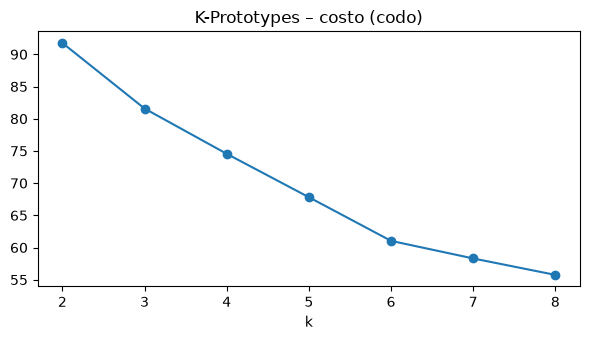

,modelo,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,ARI_sd,indice_combinado,candidato,costo
k,,,,,,,,,,,
2,K-Prototypes,0.169,0.310,0.368,0.053,59,0.981,0.027,0.166,False,91.770
3,K-Prototypes,0.140,0.289,0.362,0.046,41,0.644,0.143,0.090,True,81.585
4,K-Prototypes,0.099,0.288,0.355,0.036,29,0.490,0.095,0.048,True,74.555
5,K-Prototypes,0.108,0.274,0.356,0.033,15,0.522,0.130,0.056,True,67.815
6,K-Prototypes,0.132,0.249,0.356,0.031,15,0.582,0.125,0.077,True,61.037
7,K-Prototypes,0.143,0.239,0.356,0.032,6,0.642,0.116,0.092,False,58.305
8,K-Prototypes,0.134,0.229,0.353,0.030,14,0.529,0.080,0.071,False,55.751


In [7]:
cat_idx = [i for i, c in enumerate(VARS) if TIPOS[c] in ('cat', 'bin')]
Xk = X[VARS].copy()
for c in VARS:
    if TIPOS[c] in ('num', 'ord'):
        Xk[c] = (Xk[c] - Xk[c].min()) / (Xk[c].max() - Xk[c].min())
    else:
        Xk[c] = Xk[c].astype(str)
Xk_val = Xk.to_numpy(dtype=object)


def ajustar_kproto(Dm, k, idx):
    return KPrototypes(n_clusters=k, init='Cao', n_init=5, random_state=42).fit_predict(Xk_val[idx], categorical=cat_idx)


t_kp = tabla_k('K-Prototypes', ajustar_kproto, B=30)
t_kp['costo'] = [KPrototypes(n_clusters=k, init='Cao', n_init=5, random_state=42).fit(Xk_val, categorical=cat_idx).cost_ for k in K_RANGO]
plt.figure(figsize=(6, 3.5))
plt.plot(t_kp.index, t_kp['costo'], marker='o')
plt.title('K-Prototypes – costo (codo)')
plt.xlabel('k')
plt.tight_layout()
plt.show()
t_kp.round(3)

**Comentario 6:** K-Prototypes queda por debajo de PAM en todos los k. Su silueta, medida sobre Gower, va de 0.10 a 0.17, y en los k candidatos es poco estable (ARI de 0.49 a 0.64). Solo es muy estable con k = 2 (ARI 0.98), que no es candidato. El mejor candidato es k = 3 (silueta 0.140, ARI 0.64). La diferencia con PAM se explica porque K-Prototypes resume cada grupo con la media y la moda, y es sensible a la inicialización. PAM, en cambio, usa NNA reales como centros, con la misma distancia de Gower con la que se evalúa.

# 7. Modelo 4 – HDBSCAN (densidad) sobre Gower

HDBSCAN no necesita fijar k: busca zonas densas y deja como **ruido (−1)** a las NNA que no pertenecen a ninguna. Se prueba una grilla de `min_cluster_size` (tamaño mínimo de grupo) y `min_samples` (qué tan conservador es al declarar ruido).

In [8]:
filas = []
for mcs in [5, 8, 10, 15]:
    for ms in [None, 3, 5]:
        lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms, metric='precomputed').fit(D.copy()).labels_
        k = len(set(lab) - {-1})
        ok = lab != -1
        sil = silhouette_score(D[np.ix_(ok, ok)], lab[ok], metric='precomputed') if k > 1 else np.nan
        filas.append({'min_cluster_size': mcs, 'min_samples': ms, 'clusters': k, 'ruido_n': int((~ok).sum()),
                      'ruido_pct': round((~ok).mean() * 100, 1), 'silueta_sin_ruido': sil,
                      'tamaños': np.bincount(lab[ok]).tolist() if k else []})
t_hdb = pd.DataFrame(filas)
t_hdb.round(3)

,min_cluster_size,min_samples,clusters,ruido_n,ruido_pct,silueta_sin_ruido,tamaños
0,5,NaN,4,101,62.7,0.334,"[6, 26, 9, 19]"
1,5,3.0,10,74,46.0,0.375,"[10, 7, 10, 15, 6, 7, 5, 11, 6, 10]"
2,5,5.0,4,101,62.7,0.334,"[6, 26, 9, 19]"
3,8,NaN,0,161,100.0,NaN,[]
4,8,3.0,6,79,49.1,0.344,"[10, 10, 22, 12, 11, 17]"
5,8,5.0,3,107,66.5,0.323,"[26, 9, 19]"
6,10,NaN,0,161,100.0,NaN,[]
7,10,3.0,6,79,49.1,0.344,"[10, 10, 22, 12, 11, 17]"
8,10,5.0,2,102,63.4,0.371,"[33, 26]"
9,15,NaN,0,161,100.0,NaN,[]


**Comentario 7:** HDBSCAN confirma que **no hay grupos densos y separados que cubran a toda la población**. Con `min_cluster_size` de 8 o más y `min_samples` por defecto, declara a **todas** las NNA como ruido. Con parámetros más permisivos encuentra de 2 a 10 núcleos densos (silueta de 0.30 a 0.38 **sin contar el ruido**), pero deja fuera entre el **46 % y el 67 %** de las NNA. Un modelo que no asigna perfil a la mitad de los residentes no sirve para la planificación por perfiles, así que se usa solo como diagnóstico y no compite en la elección.

# 8. Comparación de modelos y elección

In [9]:
modelos = {'AGNES promedio': (t_avg, ajustar_agnes('average')), 'AGNES completo': (t_com, ajustar_agnes('complete')),
           'PAM': (t_pam, ajustar_pam), 'K-Prototypes': (t_kp, ajustar_kproto)}
comp = []
for nombre, (t, f) in modelos.items():
    cand = t[t['candidato']]
    if len(cand):
        k = elegir_k(t)
        comp.append(t.loc[k].to_dict() | {'modelo': nombre, 'k_elegido': k})
    else:
        comp.append({'modelo': nombre, 'k_elegido': None})
comp = pd.DataFrame(comp).set_index('modelo')[['k_elegido', 'silueta', 'cohesion_intra', 'separacion_inter', 'dunn', 'tamano_min', 'ARI_medio', 'indice_combinado']]
comp.loc['HDBSCAN (mejor de la grilla)'] = [np.nan, t_hdb['silueta_sin_ruido'].max(), np.nan, np.nan, np.nan, np.nan, np.nan, np.nan]
comp.round(3)

,k_elegido,silueta,cohesion_intra,separacion_inter,dunn,tamano_min,ARI_medio,indice_combinado
modelo,,,,,,,,
AGNES promedio,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AGNES completo,6.0,0.172,0.251,0.361,0.104,8.0,0.278,0.048
PAM,5.0,0.203,0.246,0.360,0.076,26.0,0.824,0.167
K-Prototypes,3.0,0.140,0.289,0.362,0.046,41.0,0.644,0.090
HDBSCAN (mejor de la grilla),NaN,0.375,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
MEJOR = comp['indice_combinado'].idxmax()
K = int(comp.loc[MEJOR, 'k_elegido'])
lab = modelos[MEJOR][1](D, K, np.arange(N))
lab = pd.factorize(pd.Series(lab).map(lambda v: v), sort=True)[0]          # etiquetas 0..K-1
X['cluster'] = lab
print(f'Modelo elegido: {MEJOR} con k = {K}')
print('Tamaños:', X['cluster'].value_counts().sort_index().to_dict())
if MEJOR == 'PAM':
    medoides = X.index[pam(D, K)[0]].tolist()
    print('Medoides (NNA representativas):', medoides)

Modelo elegido: PAM con k = 5
Tamaños: {0: 36, 1: 26, 2: 34, 3: 28, 4: 37}
Medoides (NNA representativas): ['PPA_FN_0145', 'PPA_FN_0048', 'PPA_FN_0022', 'PPA_FN_0064', 'PPA_FN_0107']


**Comentario 8:** El modelo elegido para la v1 es **PAM con k = 5**: índice combinado 0.167, frente a 0.090 de K-Prototypes y 0.048 de AGNES completo. Tiene la mejor cohesión entre los candidatos, una estabilidad alta (ARI 0.82) y grupos de 26 a 37 NNA. Igual hay que ser honestos con la magnitud: una **silueta de 0.20 indica una estructura débil**, con grupos reales y estables pero con fronteras difusas. Los perfiles se deben leer como **tipologías orientativas** y no como categorías cerradas. Los medoides (las NNA que mejor representan a cada grupo) se listan arriba, para que el equipo técnico pueda revisar un caso "típico" de cada perfil.

# 9. Contraste individual de edad y sexo

In [11]:
# Se ajusta el mismo modelo y k quitando **solo la edad**, **solo el sexo** y **ambas** (= v2)
contraste = []
for nombre, quitar in [('v1 completa', []), ('sin edad', ['edad_modelo']), ('sin sexo', ['sexo']), ('sin edad ni sexo', ['edad_modelo', 'sexo'])]:
    tv = {c: t for c, t in TIPOS.items() if c not in quitar}
    Dv = gower(X, tv)
    labv = modelos[MEJOR][1](Dv, K, np.arange(N))
    contraste.append({'variante': nombre, 'variables': len(tv), 'silueta (en su propia distancia)': silhouette_score(Dv, labv, metric='precomputed'),
                      'ARI con v1': adjusted_rand_score(X['cluster'], labv),
                      'V de Cramér cluster-sexo': cramer_v(labv, X['sexo']),
                      'V de Cramér cluster-hogar': cramer_v(labv, X['hogar']),
                      'η cluster-edad': np.sqrt(eta2(labv, X['edad_anios']))})
pd.DataFrame(contraste).set_index('variante').round(3)

,variables,silueta (en su propia distancia),ARI con v1,V de Cramér cluster-sexo,V de Cramér cluster-hogar,η cluster-edad
variante,,,,,,
v1 completa,13,0.203,1.000,0.610,0.395,0.468
sin edad,12,0.209,0.926,0.637,0.411,0.409
sin sexo,12,0.238,0.567,0.192,0.262,0.382
sin edad ni sexo,11,0.262,0.524,0.175,0.263,0.338


**Comentario 9:** Este es el **contraste individual de edad y sexo** que pide el documento de referencia.
- **Sin edad:** la partición casi no cambia (ARI 0.93 con la v1; silueta 0.209). La edad aporta poco por sí sola, porque su información ya está en buena parte en la permanencia (correlación 0.73).
- **Sin sexo:** la partición **cambia mucho** (ARI 0.57) y la silueta sube a 0.238. Además, la asociación de los grupos con el sexo baja de 0.61 a 0.19 y con el **hogar**, de 0.40 a 0.26. En la v1 el sexo arrastra a los grupos hacia la división por hogar (Matogroso mujeres o varones), que el documento pide **no** usar para formar perfiles.
- **Sin ambas:** se obtiene la mejor silueta (0.262), con una partición distinta (ARI 0.52).

**Conclusión:** el sexo empeora la agrupación y la desvía hacia el hogar. La edad es casi neutra, pero redundante con la permanencia. Esto justifica la **versión 2 sin edad ni sexo**, que se usan después solo para describir los perfiles.

# 10. Diagnóstico: ¿alguna variable impide una mejor agrupación?

Se retira cada variable de a una, se recalcula Gower y se vuelve a ajustar el modelo elegido en los k candidatos. Retirar una variable casi siempre sube un poco la silueta, porque hay menos dimensiones. Por eso solo se considera que una variable **perjudica** la agrupación si su retiro mejora la silueta de forma **consistente en todos los k** y en una magnitud apreciable (> 0.03 en promedio).

In [12]:
base_sil = {k: silhouette_score(D, modelos[MEJOR][1](D, k, np.arange(N)), metric='precomputed') for k in K_CANDIDATOS}
loo = {}
for v in VARS:
    Dv = gower(X, {c: t for c, t in TIPOS.items() if c != v})
    loo[v] = {k: silhouette_score(Dv, modelos[MEJOR][1](Dv, k, np.arange(N)), metric='precomputed') - base_sil[k] for k in K_CANDIDATOS}
loo = pd.DataFrame(loo).T
loo.columns = [f'Δsil k={k}' for k in K_CANDIDATOS]
loo['Δ promedio'] = loo.mean(axis=1)
loo['mejora en todos los k'] = (loo.iloc[:, :len(K_CANDIDATOS)] > 0).all(axis=1)
loo.sort_values('Δ promedio', ascending=False).round(3)

,Δsil k=3,Δsil k=4,Δsil k=5,Δsil k=6,Δsil k=7,Δ promedio,mejora en todos los k
prop_meses_sin_pti_vigente,0.023,0.085,0.047,-0.000,0.002,0.031,False
estado_pti,0.034,0.045,0.023,0.023,0.026,0.030,True
ln_permanencia,0.008,0.051,0.006,0.007,0.007,0.016,True
sexo,0.019,0.018,0.035,-0.012,0.010,0.014,False
malnutricion_flag,0.012,0.020,0.022,0.006,0.006,0.013,True
nivel_atencion_salud_mental,-0.027,0.034,0.020,0.013,0.012,0.010,False
presenta_discapacidad,0.006,0.006,0.007,0.009,0.003,0.006,True
salud_fisica_cronica,0.008,0.009,0.014,0.012,-0.013,0.006,False
situacion_juridica,0.015,0.071,-0.010,-0.032,-0.028,0.003,False
procedencia_provincias,0.009,-0.004,0.005,0.009,-0.024,-0.001,False


**Comentario 10:** Retirar cualquier variable sube un poco la silueta, como se esperaba, pero en general la mejora es pequeña y no aparece en todos los k. Dos casos merecen atención:
- **`estado_pti`** mejora en todos los k, con una media de 0.030, justo en el límite del criterio.
- **`prop_meses_sin_pti_vigente`** tiene la mejora media más alta (0.031), pero no en todos los k.

Ambas describen el PTI (estado actual e historial), así que esa dimensión entra dos veces. **Se mantienen las dos:** el PTI no vigente es uno de los dos focos explícitos del objetivo de negocio, y el historial distingue a quien recién regularizó su PTI de quien lo tuvo siempre. El sexo mejora en 3 de 5 k (+0.014 en promedio). Su efecto se ve mejor en el contraste de la sección 9, donde cambia la partición completa. **Ninguna variable se excluye en la v1** por este diagnóstico.

# 11. Sensibilidad: NNA recuperados (INC-01 / INC-06)

En el Paso 4B se recuperaron 16 NNA con correcciones que la institución todavía tiene en revisión. Se ajusta el modelo **sin ellos** y se compara la asignación de las 145 NNA restantes con la del modelo completo.

In [13]:
sin_rec = np.asarray(X['id_recuperado'] == 'No')
lab_sin = modelos[MEJOR][1](D[np.ix_(sin_rec, sin_rec)], K, np.where(sin_rec)[0])
ari_rec = adjusted_rand_score(X.loc[sin_rec, 'cluster'], lab_sin)
print(f'ARI entre el modelo completo y el modelo sin los 16 NNA recuperados (sobre las {sin_rec.sum()} NNA comunes): {ari_rec:.3f}')
print('Distribución de los recuperados por cluster:', X.loc[~sin_rec, 'cluster'].value_counts().sort_index().to_dict())

ARI entre el modelo completo y el modelo sin los 16 NNA recuperados (sobre las 145 NNA comunes): 1.000
Distribución de los recuperados por cluster: {0: 4, 1: 4, 2: 1, 3: 3, 4: 4}


**Comentario 11:** Al ajustar PAM sin los 16 NNA recuperados (INC-01 / INC-06), las 145 NNA restantes quedan **exactamente en los mismos grupos (ARI = 1.00)**. Los recuperados se reparten en los 5 grupos (4, 4, 1, 3 y 4) y no forman un grupo propio. Su inclusión no altera los perfiles, aunque la institución todavía tiene que confirmar sus datos.

# 12. Caracterización de los perfiles

In [14]:
DESCRIPTIVAS = ['edad_anios', 'sexo', 'nivel_educativo', 'hogar', 'provisional_prolongada', 'activo_al_corte', 'permanencia_cat', 'tipo_discapacidad']
imp = {}
for v in VARS + [c for c in DESCRIPTIVAS if c not in VARS]:
    es_num = TIPOS.get(v) in ('num', 'ord') or (v not in TIPOS and pd.api.types.is_numeric_dtype(X[v]) and X[v].nunique() > 2)
    imp[v] = {'asociación con el cluster': np.sqrt(eta2(X['cluster'], X[v])) if es_num else cramer_v(X['cluster'], X[v]),
              'medida': 'η' if es_num else 'V de Cramér', 'uso': 'modelo' if v in VARS else 'descriptiva'}
imp = pd.DataFrame(imp).T.sort_values('asociación con el cluster', ascending=False)
imp

,asociación con el cluster,medida,uso
prop_meses_sin_pti_vigente,0.777657,η,modelo
malnutricion_flag,0.638577,V de Cramér,modelo
sexo,0.609912,V de Cramér,modelo
estado_pti,0.569995,V de Cramér,modelo
provisional_prolongada,0.541625,V de Cramér,descriptiva
score_imc,0.492943,η,modelo
ln_permanencia,0.492397,η,modelo
edad_modelo,0.480166,η,modelo
edad_anios,0.467738,η,descriptiva
situacion_juridica,0.455445,V de Cramér,modelo


In [15]:
num_desc = ['edad_anios', 'meses_permanencia', 'nivel_atencion_salud_mental', 'score_imc', 'prop_meses_sin_pti_vigente']
perfil = X.groupby('cluster').agg(n=('cluster', 'size'), **{f'{c} (mediana)': (c, 'median') for c in num_desc})
perfil['% del total'] = (perfil['n'] / N * 100).round(1)
binarias = ['procedencia_provincias', 'salud_fisica_cronica', 'presenta_discapacidad', 'flag_rezago_escolar', 'malnutricion_flag',
            'provisional_prolongada', 'activo_al_corte']
pct = X.assign(mujer=(X['sexo'] == 'F').astype(int)).groupby('cluster')[['mujer'] + binarias].mean().mul(100).round(0)
pct.columns = [f'% {c}' for c in pct.columns]
pd.concat([perfil.round(2), pct], axis=1).T

cluster,0,1,2,3,4
n,36.00,26.00,34.00,28.00,37.00
edad_anios (mediana),7.72,11.73,12.54,13.66,7.47
meses_permanencia (mediana),32.20,84.65,53.60,115.50,39.00
nivel_atencion_salud_mental (mediana),2.00,1.00,2.00,1.00,2.00
score_imc (mediana),2.00,0.50,2.00,0.00,0.00
prop_meses_sin_pti_vigente (mediana),0.28,0.00,1.00,0.90,1.00
% del total,22.40,16.10,21.10,17.40,23.00
% mujer,17.00,88.00,79.00,32.00,19.00
% procedencia_provincias,8.00,23.00,9.00,0.00,14.00
% salud_fisica_cronica,8.00,8.00,24.00,25.00,8.00


In [16]:
for c in ['situacion_juridica', 'estado_pti', 'nivel_educativo', 'edad_cat', 'hogar']:
    print(f'\n{c} (% dentro de cada cluster)')
    print((pd.crosstab(X['cluster'], X[c], normalize='index') * 100).round(0).to_string())


situacion_juridica (% dentro de cada cluster)
situacion_juridica  1 Tutela / Medida judicial firme  2 Acogimiento residencial formal  3 Investigacion tutelar / Medida provisional  4 Sin definir / En observacion
cluster                                                                                                                                                             
0                                                3.0                              11.0                                          86.0                             0.0
1                                                0.0                               4.0                                          96.0                             0.0
2                                               15.0                               6.0                                          76.0                             3.0
3                                               86.0                               4.0                                          

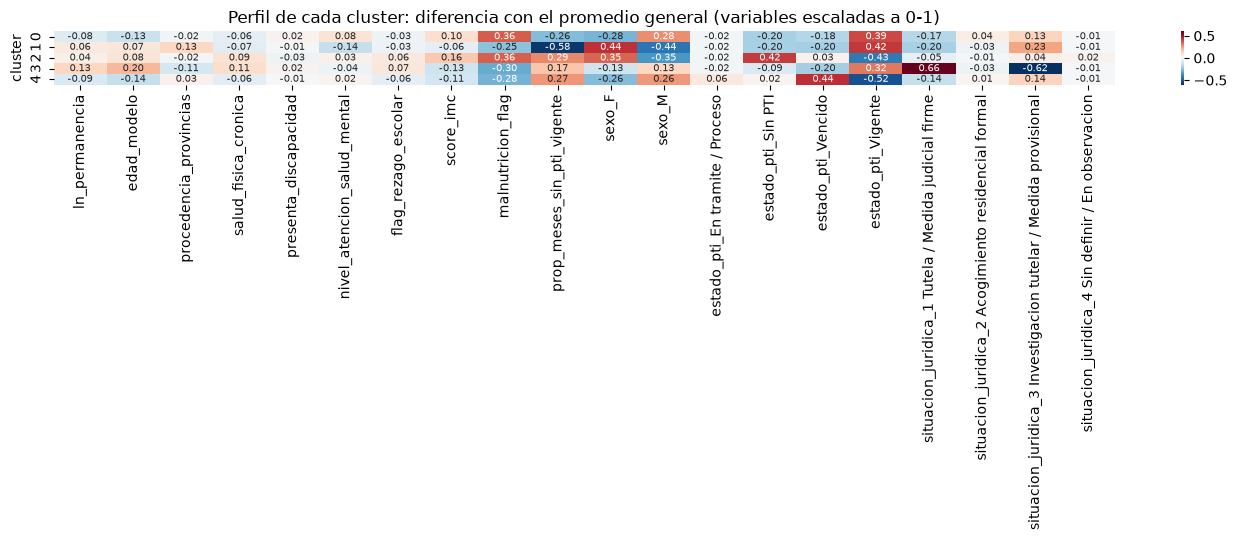

In [17]:
# Mapa de calor: diferencia de cada cluster respecto del total (variables del modelo, codificadas)
enc = pd.get_dummies(X[VARS].astype({c: str for c in VARS if TIPOS[c] == 'cat'}), dtype=float)
enc = (enc - enc.min()) / (enc.max() - enc.min())
dif = enc.groupby(X['cluster']).mean() - enc.mean()
plt.figure(figsize=(14, 0.6 * K + 2.5))
sns.heatmap(dif, cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.6, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Perfil de cada cluster: diferencia con el promedio general (variables escaladas a 0-1)')
plt.ylabel('cluster')
plt.tight_layout()
plt.show()

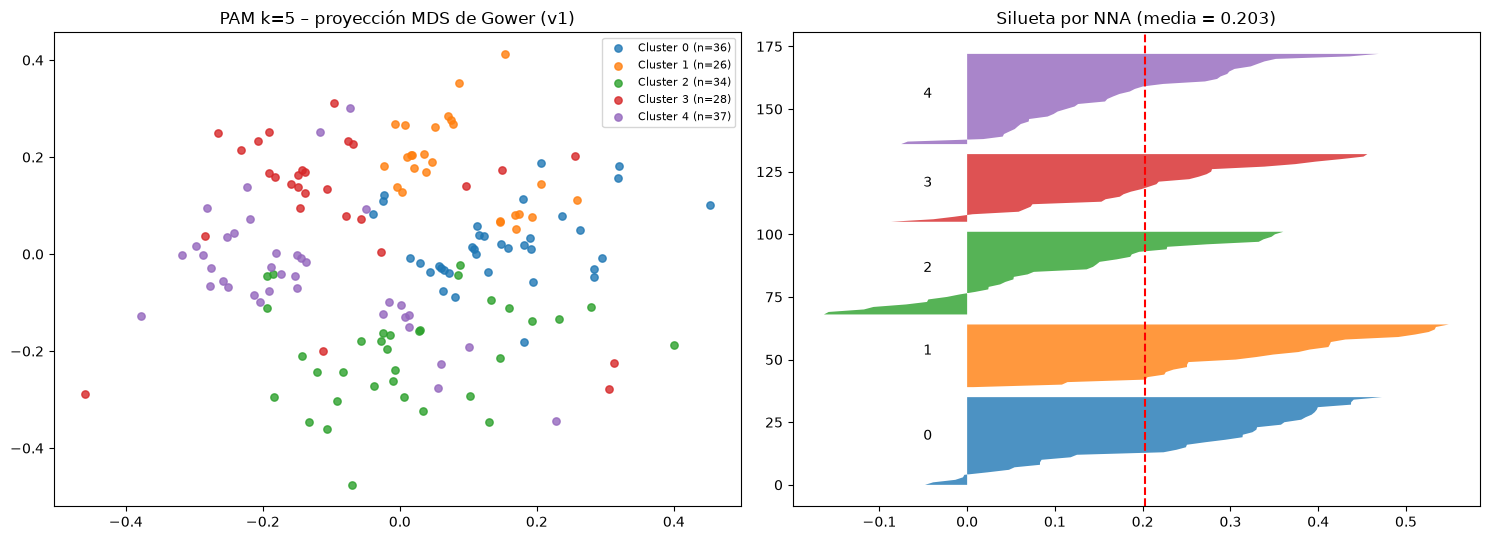

Silueta media por cluster: {0: 0.236, 1: 0.332, 2: 0.101, 3: 0.201, 4: 0.174}


In [18]:
coords = MDS(n_components=2, dissimilarity='precomputed', random_state=42, n_init=4).fit_transform(D)
sil_i = silhouette_samples(D, X['cluster'], metric='precomputed')
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
for c in range(K):
    m = (X['cluster'] == c).values
    ax[0].scatter(coords[m, 0], coords[m, 1], s=28, alpha=.8, label=f'Cluster {c} (n={m.sum()})')
ax[0].set_title(f'{MEJOR} k={K} – proyección MDS de Gower ({VERSION})')
ax[0].legend(fontsize=8)
y0 = 0
for c in range(K):
    s = np.sort(sil_i[X['cluster'] == c])
    ax[1].fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, alpha=.8)
    ax[1].text(-0.05, y0 + len(s) / 2, str(c))
    y0 += len(s) + 3
ax[1].axvline(sil_i.mean(), color='red', ls='--')
ax[1].set_title(f'Silueta por NNA (media = {sil_i.mean():.3f})')
plt.tight_layout()
plt.show()
print('Silueta media por cluster:', pd.Series(sil_i).groupby(X['cluster'].values).mean().round(3).to_dict())

**Comentario 12 – perfiles.** Las variables más asociadas a los grupos son el historial del PTI (η = 0.78), la malnutrición (V = 0.64), **el sexo (V = 0.61)** y el estado del PTI (V = 0.57). Los cinco grupos de la v1:

| Cluster | n (%) | Rasgos principales |
|---|---|---|
| **0** | 36 (22 %) | **Varones (83 %)**, niños (mediana 7.7 años), **PTI vigente (97 %)**, **malnutrición (92 %**, mediana de score = sobrepeso), medida provisional (86 %) |
| **1** | 26 (16 %) | **Mujeres (88 %)**, 11.7 años, **PTI vigente (100 %)**, **provisional prolongada (96 %)**, 7 años de permanencia, sin alerta nutricional (31 %); 58 % del hogar Matogroso mujeres |
| **2** | 34 (21 %) | **Mujeres (79 %)**, 12.5 años, **sin PTI (62 %) o vencido (24 %)**, **malnutrición (91 %)**, salud crónica (24 %), rezago (18 %). Es el grupo menos cohesionado (silueta 0.10) |
| **3** | 28 (17 %) | Adolescentes (13.7 años), **medida firme (86 %)**, **9.6 años de permanencia**, PTI vigente hoy (89 %) pero ausente en la mayor parte del historial, sin alerta nutricional; 54 % de Matogroso hombres |
| **4** | 37 (23 %) | **Varones (81 %)**, niños (7.5 años), **PTI vencido (65 %) o sin PTI (22 %)**, medida provisional (86 %), sin alerta nutricional (73 %) |

Los grupos combinan PTI, nutrición y situación legal, pero **el sexo los divide en pares** (0 y 4 son varones, 1 y 2 son mujeres) y el hogar acompaña esa división. Para el equipo técnico, que un perfil sea de varones o de mujeres no cambia la intervención, mientras que la situación del PTI o la nutrición sí. Esto refuerza la decisión de probar la v2.

# 13. Guardado

In [19]:
salida = X[['id_original', 'cluster'] + VARS + [c for c in DESCRIPTIVAS if c not in VARS]].copy()
salida['silueta_individual'] = sil_i.round(3)
resumen_modelos = pd.concat([t_avg, t_com, t_pam, t_kp])
with pd.ExcelWriter(RUTA / f'Clusters_{VERSION}.xlsx') as w:
    salida.reset_index().to_excel(w, sheet_name='asignacion', index=False)
    resumen_modelos.reset_index().to_excel(w, sheet_name='metricas_por_k', index=False)
    comp.reset_index().to_excel(w, sheet_name='comparacion_modelos', index=False)
    t_hdb.to_excel(w, sheet_name='hdbscan', index=False)
    loo.reset_index().to_excel(w, sheet_name='diagnostico_variables', index=False)
    imp.reset_index().to_excel(w, sheet_name='importancia', index=False)
print('Guardado:', (RUTA / f'Clusters_{VERSION}.xlsx').relative_to(BASE))

Guardado: Resultados_EnfoqueB\Clusters_v1.xlsx


**Comentario 13:** La asignación de la v1 (cluster, silueta individual y variables) y todas las métricas se guardan en `Resultados_EnfoqueB/Clusters_v1.xlsx`. **Resumen de la v1:** PAM con k = 5 es estable (ARI 0.82), pero su estructura es débil (silueta 0.20) y el sexo la condiciona, lo que la acerca a la división por hogar. La versión 2 retira la edad y el sexo, y el notebook `Paso 7 - Clustering v3 (MCA reducido) y comparacion final` compara las tres versiones. La elección final se hace en el Paso 8.